# Blend results viewer

Reads the results saved by the `blend_weights_ELT` / `blend_weights_YLT` notebooks (`<RUNS_DIR>/<timestamp>__<section>/results.csv`)
and plots the optimal weights. Set the options below, run the definitions cell once, then any section.

| Option | Meaning |
|---|---|
| `RUNS_DIR` | `results/blend_runs_ELT` (ELT) or `results/blend_runs` (YLT) |
| `RUN_STAMP` | `None` = latest run of each section; or a timestamp prefix, e.g. `'20261024_12'` |
| `SCORING_RULES` | list of rule names to keep (e.g. `['CRPS', 'LogScore']`), or `None` for all. Not applied to quantile windows (3- or 2-model) |
| `TARGETS` | list of target models to keep, or `None` for all |

In [ ]:
RUNS_DIR = "results/blend_runs"      # YLT: "results/blend_runs"
RUN_STAMP = None
SCORING_RULES = None                     # e.g. ['CRPS', 'LogScore', 'QuantileWeightedCRPS']
# TARGETS = ['IBTrACS', 'IBTrACS_p', 'WN_MiniTC_repeat', 'WN_MiniTC_perturb']                        # e.g. ['IBTrACS', 'IBTrACS_p']
TARGETS = ['IBTrACS', 'IBTrACS_p', 'MINI-WNC']  


In [ ]:
import re
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

MODEL_COLOURS = {'STORM': '#4C72B0', 'CHAZ': '#C44E52', 'IRIS': '#55A868'}


def load_results(runs_dir, stamp=None):
    """{section: DataFrame} from <runs_dir>/<timestamp>__<section>/results.csv. Uses the latest run of each
    section, or only runs whose timestamp starts with `stamp` (e.g. '20261024_12')."""
    out = {}
    for d in sorted(Path(runs_dir).glob('*__*')):              # folder names sort by timestamp
        stamp_d, section = d.name.split('__', 1)
        if (d / 'results.csv').exists() and (stamp is None or stamp_d.startswith(stamp)):
            out[section] = pd.read_csv(d / 'results.csv').assign(run=stamp_d)
    if not out:
        raise FileNotFoundError(f"no saved runs in {Path(runs_dir).resolve()}" + (f" matching {stamp!r}" if stamp else ""))
    return out


def condition_label(df):
    """Readable condition per row: 'All', the loss range, 'X <= u', or the note (e.g. 'own q=1')."""
    lab = pd.Series('All', index=df.index)
    if 'loss_range' in df:
        lab = lab.where(df['loss_range'].fillna('All') == 'All', df['loss_range'])
    if 'condition_below' in df:
        m = df['condition_below'].notna()
        lab[m] = 'X <= ' + df.loc[m, 'condition_below'].map('{:.3g}'.format)
    if 'note' in df:
        m = df['note'].notna()
        lab[m] = df.loc[m, 'note']
    return lab


def prepare(results, rules=None, targets=None):
    """Adds a `condition` column and applies the scoring-rule and target filters to every section.
    The rule filter is not applied to quantile-window sections (their rules are the windows)."""
    out = {}
    for section, df in results.items():
        df = df.assign(condition=condition_label(df))
        if rules is not None and 'quantile_windows' not in section:
            df = df[df['scoring_rule'].isin(rules)]
        if targets is not None:
            df = df[df['target'].isin(targets)]
        out[section] = df
    return out


def models_in(df):
    return list(dict.fromkeys(m for c in df['components'].dropna() for m in c.split('+')))


def colour(m, i):
    return MODEL_COLOURS.get(m, f'C{i}')


def weights_table(df, index=('target', 'scoring_rule')):
    """Weights per row as a table (shaded 0 -> 1), plus the dominant model and mean score."""
    cols = [f'weight_{m}' for m in models_in(df)]
    t = df.set_index(list(index))[cols + ['dominant_model', 'min_mean_score']].rename(columns=lambda c: c.replace('weight_', ''))
    return t.style.background_gradient(cmap='Blues', vmin=0, vmax=1, subset=[c[7:] for c in cols]).format(
        {c[7:]: '{:.2f}' for c in cols} | {'min_mean_score': '{:.4g}'})


def plot_weights(df, y='scoring_rule', row='target', col=None, title=''):
    """Small multiples of stacked horizontal weight bars: one bar per value of `y`, one panel per row (x col)."""
    if df.empty:
        print(f"nothing to plot for {title!r} (check the filters)")
        return
    models, ys = models_in(df), list(dict.fromkeys(df[y]))
    rows = list(dict.fromkeys(df[row])) if row else [None]
    cols = list(dict.fromkeys(df[col])) if col else [None]
    fig, axes = plt.subplots(len(rows), len(cols), squeeze=False, sharex=True, sharey=True,
                             figsize=(2.6 * len(cols) + 2.2, 0.28 * len(ys) * len(rows) + 0.6 * len(rows) + 0.8))
    for i, r in enumerate(rows):
        for j, c in enumerate(cols):
            ax, sub = axes[i, j], df
            if row:
                sub = sub[sub[row] == r]
            if col:
                sub = sub[sub[col] == c]
            sub = sub.drop_duplicates(y, keep='last').set_index(y).reindex(ys)
            if sub[[f'weight_{m}' for m in models]].isna().all().all():
                ax.text(0.5, 0.5, 'no results', transform=ax.transAxes, ha='center', color='0.5')
            left = np.zeros(len(ys))
            for k, m in enumerate(models):
                w = sub[f'weight_{m}'].fillna(0).to_numpy()
                ax.barh(range(len(ys)), w, left=left, color=colour(m, k), label=m, height=0.8)
                left += w
            ax.set_yticks(range(len(ys)), ys, fontsize=8)
            ax.set_xlim(0, 1)
            ax.invert_yaxis() if i == 0 and j == 0 else None
            if col is None:
                ax.set_title(str(r) if r is not None else '', fontsize=9)
            else:
                if i == 0:
                    ax.set_title(str(c), fontsize=9)
                if j == 0 and r is not None:
                    ax.set_ylabel(str(r), fontsize=9, fontweight='bold')
    axes[0, -1].legend(loc='upper left', bbox_to_anchor=(1.02, 1), fontsize=8)
    fig.suptitle(title, y=1.0)
    plt.tight_layout(); plt.show()


def plot_windows(df, title='Quantile windows'):
    """Weight of each model against the centre of the quantile window, one panel per target."""
    if df.empty:
        print("nothing to plot (check the filters)")
        return
    df = df.assign(centre=df['scoring_rule'].map(lambda s: np.mean([float(v) for v in re.findall(r'[\d.]+', s)])))
    models, targets = models_in(df), list(dict.fromkeys(df['target']))
    ncol = min(3, len(targets))
    nrow = int(np.ceil(len(targets) / ncol))
    fig, axes = plt.subplots(nrow, ncol, figsize=(4.2 * ncol + 1.2, 3.2 * nrow), squeeze=False, sharey=True)
    for ax, t in zip(axes.flat, targets):
        sub = df[df['target'] == t].sort_values('centre')
        for k, m in enumerate(models):
            ax.plot(sub['centre'], sub[f'weight_{m}'], marker='o', color=colour(m, k), label=m)
        ax.set(title=t, xlabel='window centre (quantile level)', ylim=(-0.03, 1.03), xlim=(0, 1))
        ax.grid(alpha=0.3)
    for ax in axes.flat[len(targets):]:
        ax.axis('off')
    axes[0, 0].set_ylabel('weight')
    axes[0, -1].legend(loc='upper left', bbox_to_anchor=(1.02, 1))
    fig.suptitle(title, y=1.0)
    plt.tight_layout(); plt.show()


def plot_subsample(df, stat='median', title='Subsampling'):
    """Weight `stat` ('median' or 'mean') with its 2.5-97.5% subsample interval, per scoring rule; one panel per
    target (rows) and condition (columns)."""
    if df.empty:
        print("nothing to plot (check the filters)")
        return
    models, rules = models_in(df), list(dict.fromkeys(df['scoring_rule']))
    targets, conds = list(dict.fromkeys(df['target'])), list(dict.fromkeys(df['condition']))
    fig, axes = plt.subplots(len(targets), len(conds), squeeze=False, sharex=True, sharey=True,
                             figsize=(0.55 * len(rules) * len(conds) + 2.5, 2.6 * len(targets) + 0.8))
    x = np.arange(len(rules))
    off = np.linspace(-0.25, 0.25, len(models))
    for i, t in enumerate(targets):
        for j, c in enumerate(conds):
            ax = axes[i, j]
            sub = df[(df['target'] == t) & (df['condition'] == c)].drop_duplicates('scoring_rule', keep='last')
            sub = sub.set_index('scoring_rule').reindex(rules)
            if sub[[f'weight_{m}_{stat}' for m in models]].isna().all().all():
                ax.text(0.5, 0.5, 'no results', transform=ax.transAxes, ha='center', color='0.5')
            for k, m in enumerate(models):
                mid, lo, hi = (sub[f'weight_{m}_{s}'].to_numpy() for s in (stat, 'q025', 'q975'))
                ax.errorbar(x + off[k], mid, yerr=[mid - lo, hi - mid], fmt='o', ms=4, capsize=2,
                            color=colour(m, k), label=m)
            ax.set_ylim(-0.05, 1.05)
            if i == 0:
                ax.set_title(str(c), fontsize=9)
            if j == 0:
                ax.set_ylabel(str(t), fontsize=9, fontweight='bold')
            ax.set_xticks(x, rules, rotation=60, ha='right', fontsize=8)
            ax.grid(alpha=0.3, axis='y')
    axes[0, -1].legend(loc='upper left', bbox_to_anchor=(1.02, 1), fontsize=8)
    fig.suptitle(title, y=1.0)
    plt.tight_layout(); plt.show()


def plot_ternary(df, colour_by='scoring_rule', marker_by='target', title=''):
    """Each (target, rule) optimum as a point in the weight triangle (3-model blends only); corners = one model."""
    models = models_in(df)
    if len(models) != 3 or df.empty:
        print("ternary plot needs non-empty results for exactly three models")
        return
    W = df[[f'weight_{m}' for m in models]].fillna(0).to_numpy()
    corners = np.array([[0, 0], [1, 0], [0.5, np.sqrt(3) / 2]])
    xy = W @ corners
    fig, ax = plt.subplots(figsize=(7.5, 6.5))
    ax.plot(*np.vstack([corners, corners[:1]]).T, color='k', lw=1)
    for (cx, cy), m, dy in zip(corners, models, (-0.06, -0.06, 0.03)):
        ax.text(cx, cy + dy, m, ha='center', fontsize=11, color=MODEL_COLOURS.get(m, 'k'))
    for g in (0.25, 0.5, 0.75):                                   # grid: lines of constant weight g on one model
        for k in range(3):
            a, b = [i for i in range(3) if i != k]
            ends = np.array([g * corners[k] + (1 - g) * corners[a], g * corners[k] + (1 - g) * corners[b]])
            ax.plot(*ends.T, color='0.85', lw=0.6, zorder=0)
    groups_c = list(dict.fromkeys(df[colour_by]))
    groups_m = list(dict.fromkeys(df[marker_by]))
    markers = 'osD^vP*Xh<>'
    for (cv, mv), idx in df.groupby([colour_by, marker_by], sort=False).groups.items():
        pts = xy[df.index.get_indexer(idx)]
        ax.scatter(pts[:, 0], pts[:, 1], s=60, alpha=0.75, color=f'C{groups_c.index(cv) % 10}',
                   marker=markers[groups_m.index(mv) % len(markers)], edgecolor='k', linewidth=0.4)
    handles = ([plt.Line2D([], [], ls='', marker='o', color=f'C{i % 10}', label=v) for i, v in enumerate(groups_c)]
               + [plt.Line2D([], [], ls='', marker=markers[i % len(markers)], color='0.4', label=v)
                  for i, v in enumerate(groups_m)])
    ax.legend(handles=handles, loc='upper left', bbox_to_anchor=(1.0, 1), fontsize=8)
    ax.set(xlim=(-0.08, 1.08), ylim=(-0.1, 0.95), aspect='equal', title=title)
    ax.axis('off')
    plt.tight_layout(); plt.show()


## Load

In [ ]:
raw = load_results(RUNS_DIR, RUN_STAMP)
res = prepare(raw, SCORING_RULES, TARGETS)
pd.DataFrame({s: {'run': d['run'].iloc[0] if len(d) else None, 'rows': len(d),
                  'targets': d['target'].nunique(), 'rules': d['scoring_rule'].nunique(),
                  'conditions': d['condition'].nunique()} for s, d in res.items()}).T


,run,rows,targets,rules,conditions
conditional,20261025_010432,117,3,13,3
conditional_own,20261025_010432,39,3,13,1
quantile_windows,20261025_010432,27,3,9,1
standard,20261025_010432,18,3,6,1
subsample,20261025_010432,72,3,6,4


## 1. Standard scores
Table: weights per target and rule (shaded 0 to 1). Plot: one panel per target, one stacked bar per rule.

In [ ]:
weights_table(res['standard'])


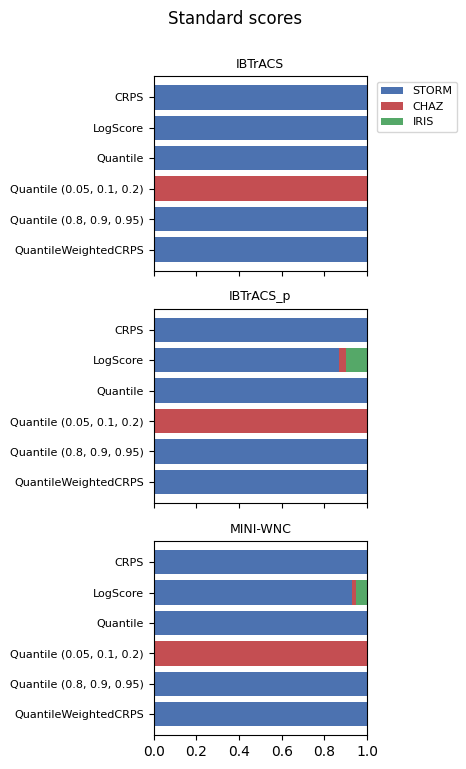

In [ ]:
plot_weights(res['standard'], y='scoring_rule', row='target', title='Standard scores')


## 2. Quantile windows
How the weights move from low-loss windows (left) to high-loss windows (right).

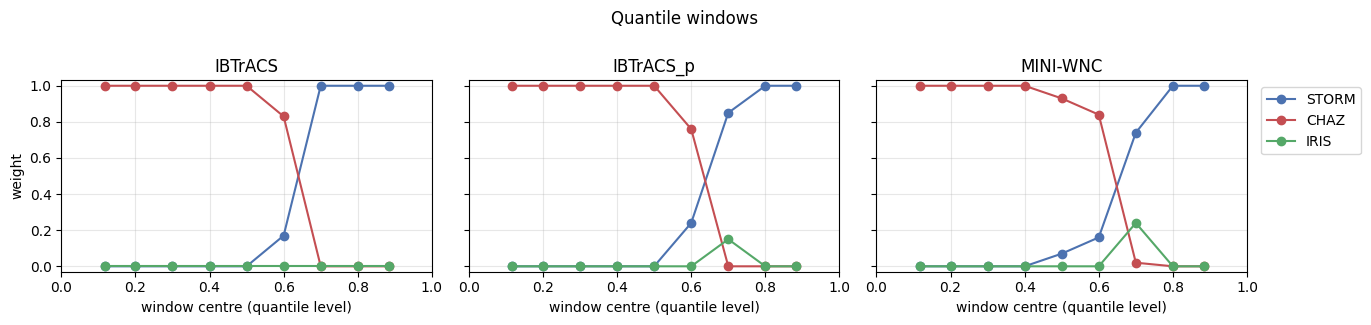

In [ ]:
plot_windows(res['quantile_windows'])


## 3. All conditions side by side
Unconditional (`All`), the shared thresholds (section 3) and each target's own threshold (section 4) together:
rows are targets, columns are scoring rules, bars are conditions. Narrow `SCORING_RULES` if this is too wide.

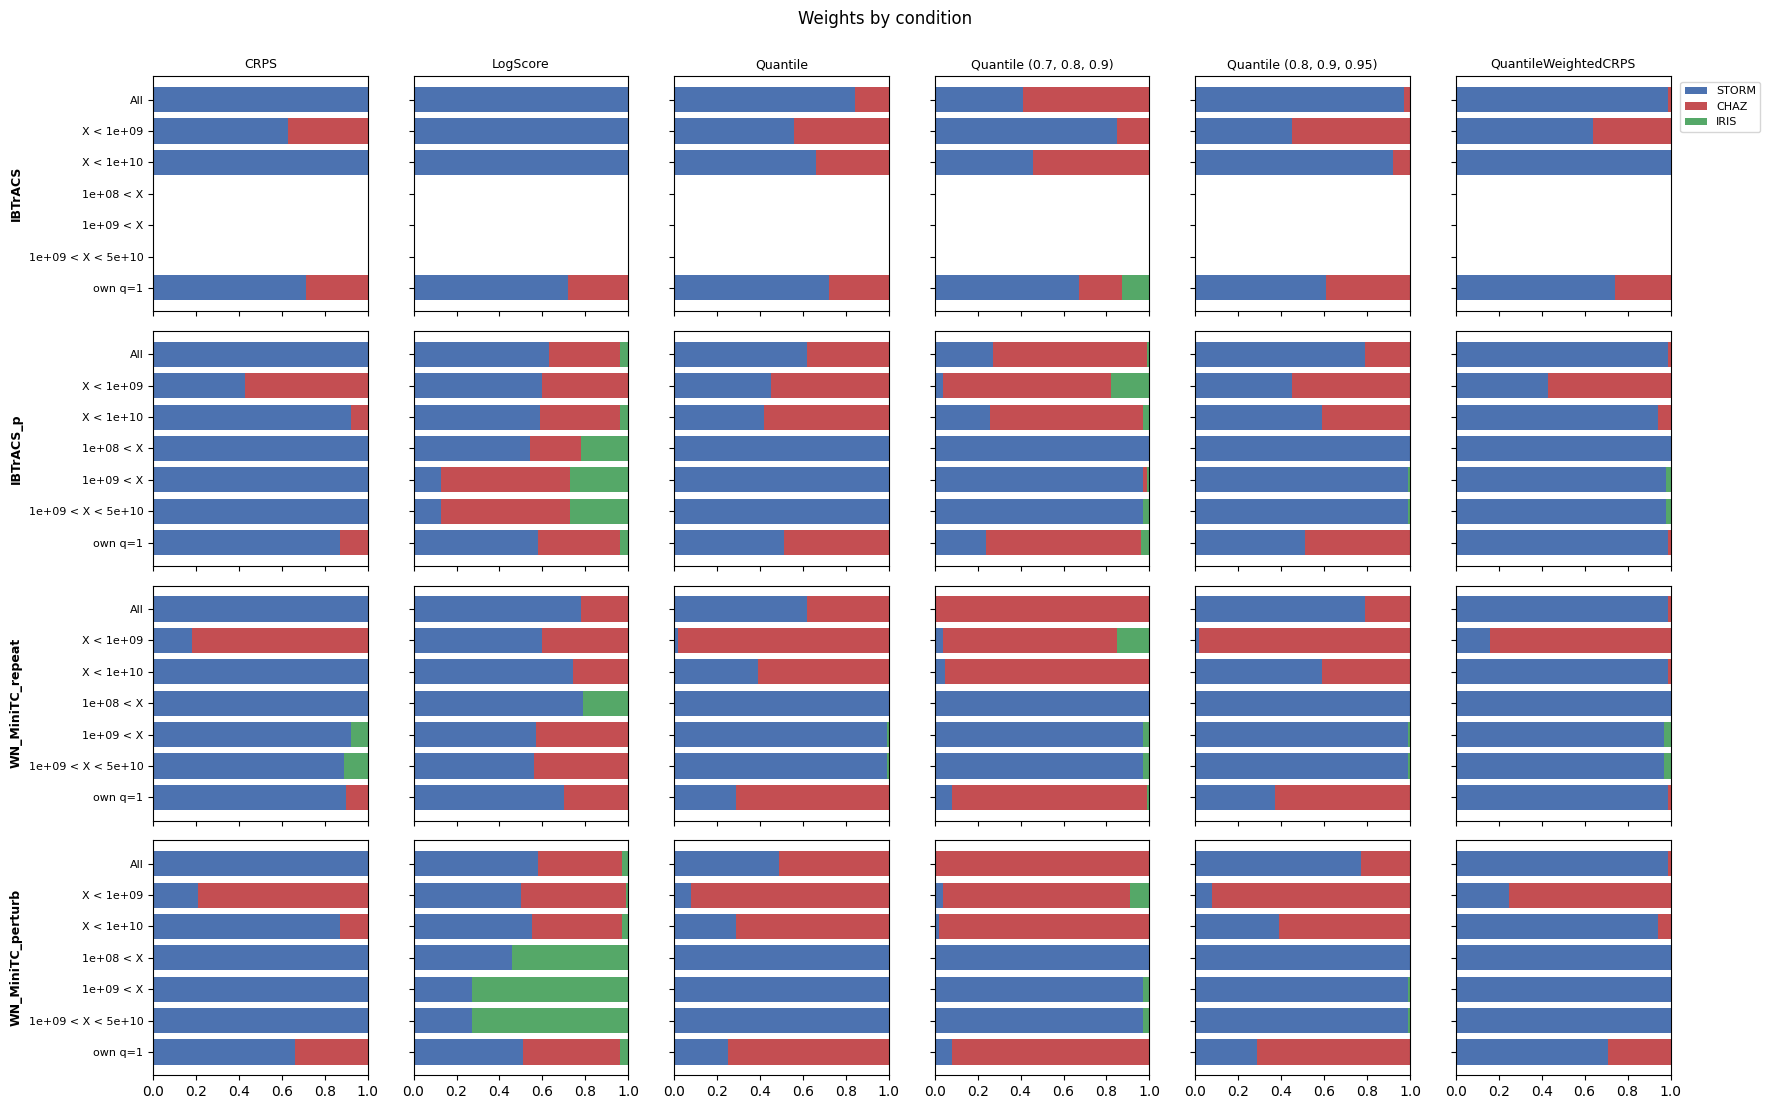

In [ ]:
cond = pd.concat([res[s] for s in ('standard', 'conditional', 'conditional_own') if s in res], ignore_index=True)
cond = cond[cond['scoring_rule'].isin(res['standard']['scoring_rule'].unique())]     # standard rules only
plot_weights(cond, y='condition', row='target', col='scoring_rule', title='Weights by condition')


In [ ]:
weights_table(cond, index=('target', 'scoring_rule', 'condition'))


## 4. Subsampling
Median weight with its 2.5-97.5% interval across subsamples; rows are targets, columns are conditions.
`frac_at_corner` in the table is the share of subsamples where one model took all the weight.

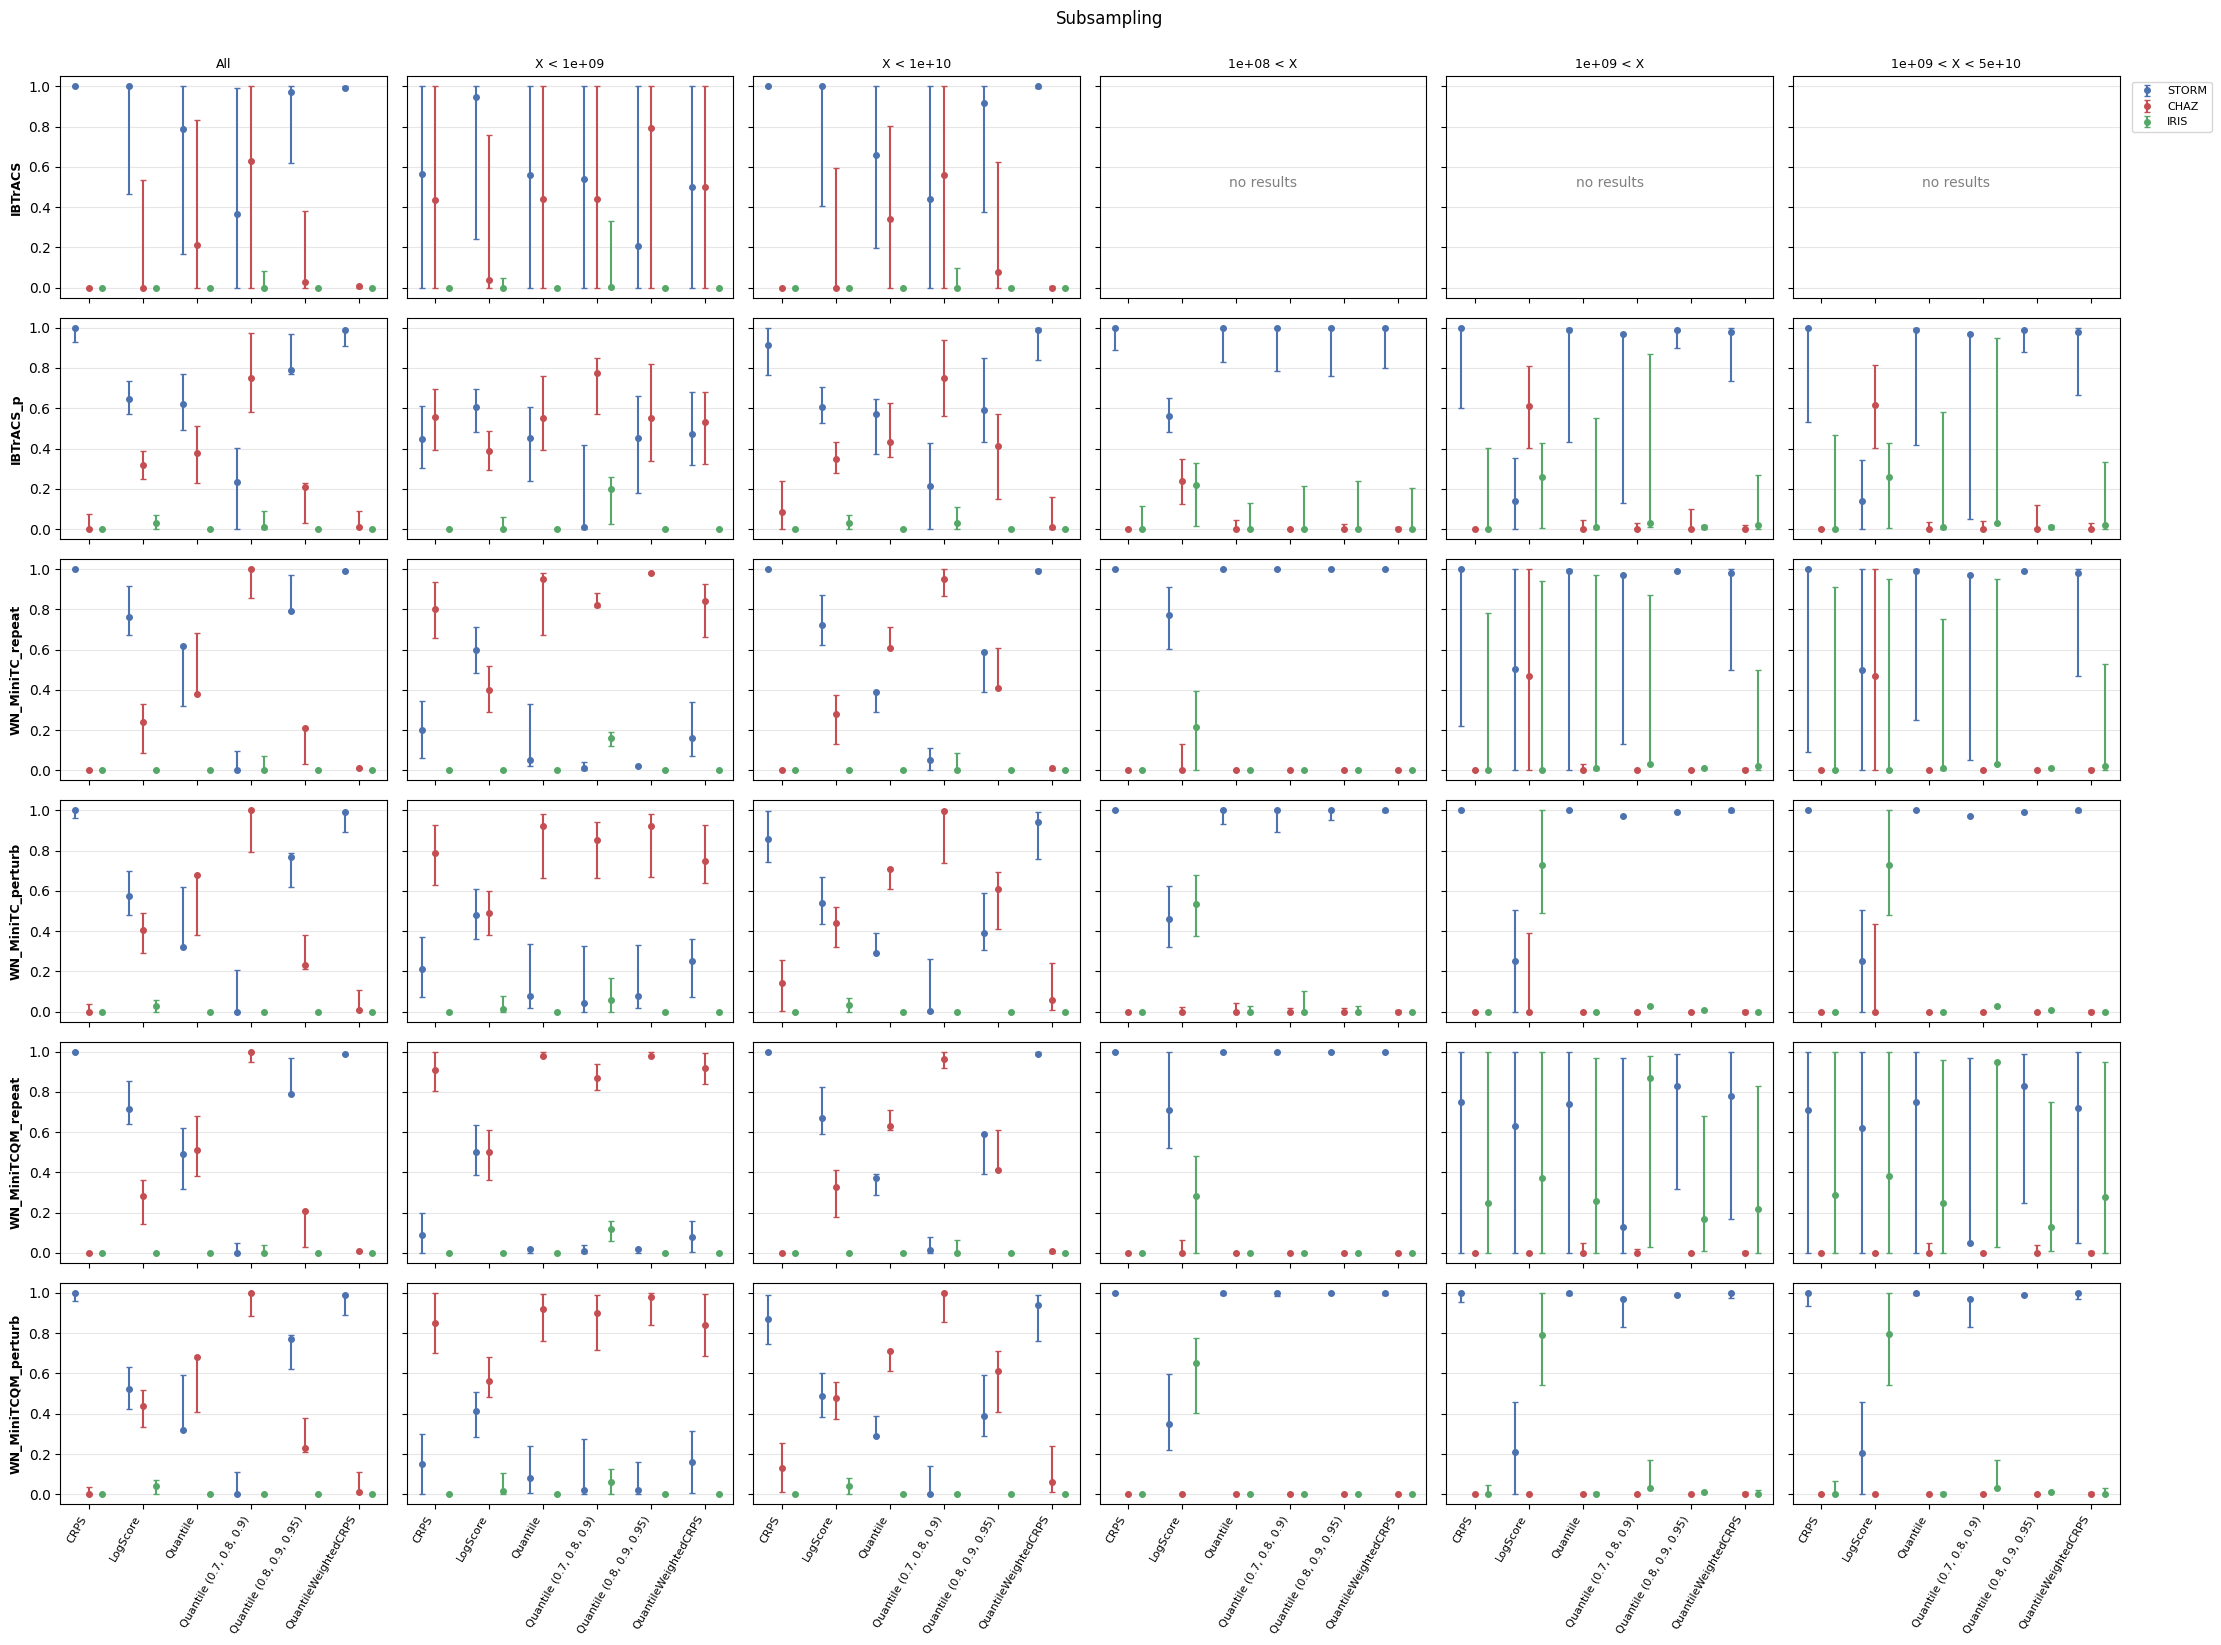

In [ ]:
plot_subsample(res['subsample'], stat='median')


In [ ]:
sub_cols = ['target', 'scoring_rule', 'condition'] + [c for c in res['subsample'].columns
                                                      if c.endswith(('_median', '_q025', '_q975'))] + ['frac_at_corner']
res['subsample'][sub_cols].round(2)


,target,scoring_rule,condition,weight_STORM_q025,weight_STORM_median,weight_STORM_q975,weight_CHAZ_q025,weight_CHAZ_median,weight_CHAZ_q975,weight_IRIS_q025,weight_IRIS_median,weight_IRIS_q975,frac_at_corner
0,IBTrACS,CRPS,All,1.00,1.00,1.00,0.0,0.00,0.00,0.00,0.00,0.00,1.00
1,IBTrACS,LogScore,All,0.46,1.00,1.00,0.0,0.00,0.54,0.00,0.00,0.00,0.78
2,IBTrACS,Quantile,All,0.16,0.79,1.00,0.0,0.21,0.83,0.00,0.00,0.00,0.10
3,IBTrACS,"Quantile (0.7, 0.8, 0.9)",All,0.00,0.36,0.99,0.0,0.63,1.00,0.00,0.00,0.09,0.32
4,IBTrACS,"Quantile (0.8, 0.9, 0.95)",All,0.62,0.97,1.00,0.0,0.03,0.38,0.00,0.00,0.00,0.10
...,...,...,...,...,...,...,...,...,...,...,...,...,...
193,WN_MiniTCQM_perturb,LogScore,1e+09 < X < 5e+10,0.00,0.20,0.46,0.0,0.00,0.00,0.54,0.80,1.00,0.38
194,WN_MiniTCQM_perturb,Quantile,1e+09 < X < 5e+10,0.99,1.00,1.00,0.0,0.00,0.00,0.00,0.00,0.01,0.88
195,WN_MiniTCQM_perturb,"Quantile (0.7, 0.8, 0.9)",1e+09 < X < 5e+10,0.83,0.97,0.97,0.0,0.00,0.00,0.03,0.03,0.17,0.00
196,WN_MiniTCQM_perturb,"Quantile (0.8, 0.9, 0.95)",1e+09 < X < 5e+10,0.99,0.99,0.99,0.0,0.00,0.00,0.01,0.01,0.01,0.00


## 5. Weight triangle
Every optimum as a point in the STORM-CHAZ-IRIS triangle: corners are single-model solutions, the centre is an
equal blend. Colour = scoring rule, marker = target.

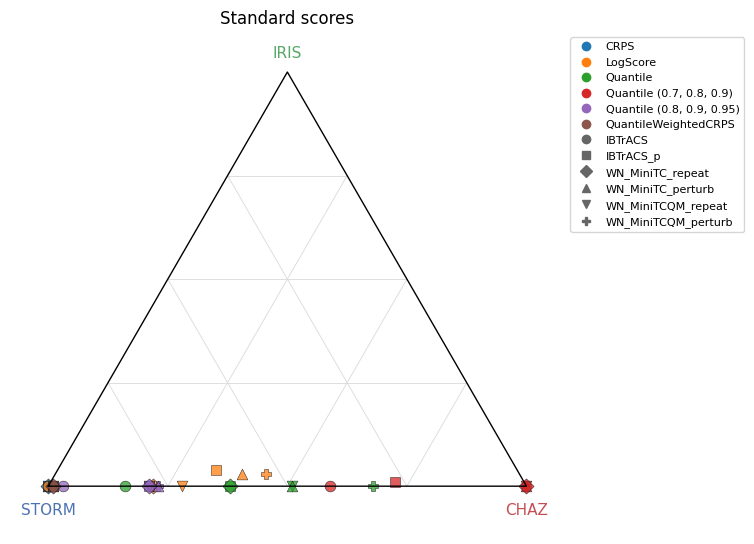

In [ ]:
plot_ternary(res['standard'], title='Standard scores')


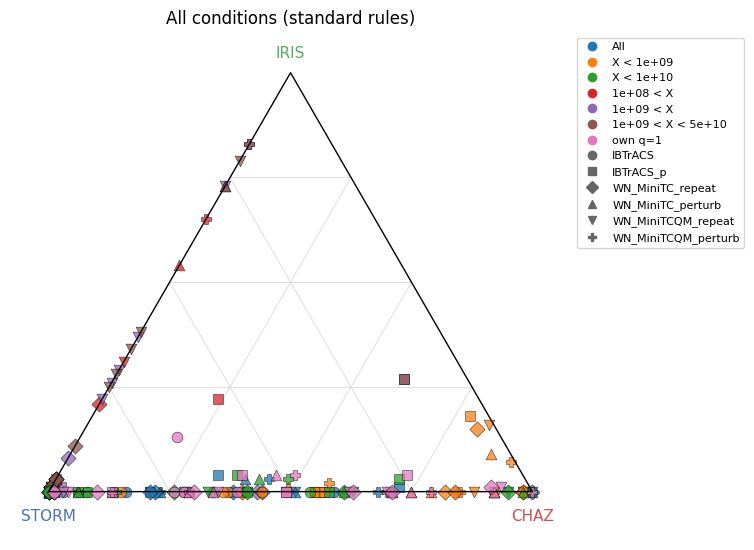

In [ ]:
plot_ternary(cond, colour_by='condition', marker_by='target', title='All conditions (standard rules)')


## 6. Model pairs
The 2-model blends (STORM+CHAZ, STORM+IRIS, CHAZ+IRIS) from section 5 of the blend notebooks. First the weights,
then what dropping each model costs: the pair's mean score relative to the 3-model blend for the same target, rule
and condition (% worse; about 0 means the dropped model adds nothing, large means it is needed).

In [ ]:
def pair_cost(pairs, triple, keys=('target', 'scoring_rule', 'condition')):
    """% by which each 2-model blend's mean score exceeds the 3-model blend's, for the same target, rule and
    condition. Columns are named by the model left out. The 3-model score is the last column."""
    keys = list(keys)
    full = models_in(triple)
    t = triple.drop_duplicates(keys, keep='last').set_index(keys)['min_mean_score']
    p = pairs.pivot_table(index=keys, columns='components', values='min_mean_score', aggfunc='last')
    out = p.sub(t, axis=0).div(t.abs(), axis=0) * 100
    out.columns = [f"without {'+'.join(m for m in full if m not in c.split('+'))} (%)" for c in out.columns]
    return out.join(t.rename('3-model score'), how='inner').round(2)


have_pairs = [s for s in ('pairs_standard', 'pairs_quantile_windows', 'pairs_conditional') if s in res]
print('pair sections found:', have_pairs or 'none - run section 5 of the blend notebook and save')

In [ ]:
plot_weights(res['pairs_standard'], y='scoring_rule', row='target', col='components', title='Model pairs: standard scores')

In [ ]:
pair_cost(res['pairs_standard'], res['standard'])

In [ ]:
for comp, d in res['pairs_quantile_windows'].groupby('components', sort=False):
    plot_windows(d, title=f'Quantile windows: {comp}')

In [ ]:
plot_weights(res['pairs_conditional'][res['pairs_conditional']['scoring_rule'].isin(res['standard']['scoring_rule'].unique())],
             y='scoring_rule', row='target', col='components', title='Model pairs: conditional (standard rules)')

In [ ]:
pair_cost(res['pairs_conditional'], res['conditional'])